# 1 · Placing every member of Congress on a map, from their votes alone

**The idea:** members who vote alike probably think alike. Lay every recorded vote out as a table,
one row per member, one column per vote, yes = 1, no = 0, and find a position for each member that
explains the pattern. Political scientists call it an *ideal point*.

**The data:** Voteview's record of every House roll call in the 118th Congress (2023-24). We drop
near-unanimous votes (fewer than 2.5% on the losing side: naming post offices tells us nothing) and
members with fewer than 20 votes.

**The known answers:**
1. a *synthetic* Congress where we chose every member's position, so recovery can be measured exactly;
2. **DW-NOMINATE**, political science's standard scores. A useful comparison, but itself a model,
   not the truth.

In [1]:
%matplotlib inline
import os, json, warnings
os.chdir('..')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ideology import plot
plot.style()
pd.set_option('display.width', 160)

from ideology import matrix, embed, evaluate, simulate, polarization, cluster
m = matrix.build(118, 'H')
info = matrix.with_members(m, 118, 'H')
print(matrix.summary(m))
print(info.party.value_counts().to_dict())
print('roll calls where most Democrats and most Republicans voted opposite ways:',
      round(polarization.party_line_share(m[info.party.isin(['Democrat', 'Republican']).values],
                                          info.party[info.party.isin(['Democrat', 'Republican'])].values), 3))

{'legislators': 451, 'roll_calls': 1119, 'missing_share': 0.07046797009525055, 'yea_share': 0.5261753207164266}
{'Republican': 230, 'Democrat': 221}
roll calls where most Democrats and most Republicans voted opposite ways: 0.778


## 1 · What the vote table looks like

How often each pair of members voted the same way, members sorted left to right by the position found
below. Two solid blocks: within a party, members agree on most contested votes; across parties, rarely.

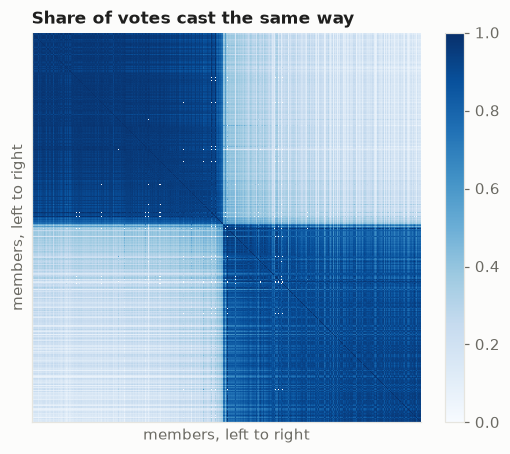

In [2]:
right = (info.party == 'Republican').to_numpy()
z, _ = embed.lpca(m, 2, right_mask=right)
order = np.argsort(z[:, 0])
A = cluster.agreement(m)[np.ix_(order, order)]
fig, ax = plt.subplots(figsize=(5.5, 4.6))
im = ax.imshow(A, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
ax.set_title('Share of votes cast the same way'); ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel('members, left to right'); ax.set_ylabel('members, left to right')
fig.colorbar(im, ax=ax, fraction=0.046); ax.grid(False)

## 2 · Which method recovers positions? The synthetic Congress

We generated 440 members in six factions with known positions on two dimensions: left-right, and an
"against the leadership" dimension on which one Republican faction stands apart. Votes are noisy, and
missed votes are not random (chronic absentees, members who served part of the term).

- **PCA** treats yes/no as numbers and fills each missed vote with that vote's average.
- **Logistic PCA** models the *probability* of a yes and simply skips missed votes.

Scores: correlation with the true left-right position across everyone, then the real test, the
rank correlation *within each party*, and how well the full 2-D map is recovered (1.0 = exact).

In [3]:
pd.read_csv('results/synthetic_positions.csv').round(3)

,method,overall_r,within_D_spearman,within_R_spearman,procrustes_r2_2d
0,PCA,0.986,0.879,0.905,0.605
1,logistic PCA,0.999,0.992,0.990,0.945


Both separate the parties (overall r ≈ 0.99). Within a party, logistic PCA orders members almost
perfectly and recovers the 2-D map far better. Where PCA goes wrong: absentees.

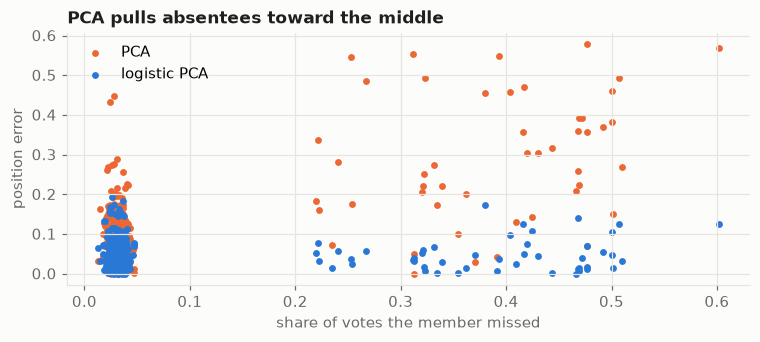

In [4]:
c = simulate.simulate()
R = (c.members.party == 'R').to_numpy()
zp, zl = embed.pca(c.votes, 1, R)[:, 0], embed.lpca(c.votes, 1, right_mask=R)[0][:, 0]
t = c.members.x1.to_numpy()
miss = c.votes.isna().mean(1).to_numpy()
def err(z):  # distance from the truth after putting both on the same scale
    a, b = np.polyfit(z, t, 1); return np.abs(a * z + b - t)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(miss, err(zp), s=12, color=plot.SERIES[1], label='PCA')
ax.scatter(miss, err(zl), s=12, color=plot.SERIES[0], label='logistic PCA')
ax.set_xlabel('share of votes the member missed'); ax.set_ylabel('position error')
ax.set_title('PCA pulls absentees toward the middle'); ax.legend()
plt.tight_layout()

## 3 · Real votes: how many dimensions, and is the model worth it?

No answer key here, so we hide a random 10% of the recorded votes, fit on the rest, and predict the
hidden ones. The rival to beat is trivial: **"vote with your party's majority"**.

In [5]:
h = pd.read_csv('results/heldout_118H.csv')
h['setting'] = np.where(h.d == 0, 'party-majority rule', 'logistic PCA, ' + h.d.astype(str) + ' dim, penalty ' + h.lam.astype(str))
h[['setting', 'accuracy', 'log_loss']].sort_values('accuracy', ascending=False).round(4).head(8)

,setting,accuracy,log_loss
8,"logistic PCA, 3 dim, penalty 0.3",0.9629,0.0944
9,"logistic PCA, 3 dim, penalty 1.0",0.9624,0.0965
10,"logistic PCA, 3 dim, penalty 3.0",0.9610,0.1041
4,"logistic PCA, 2 dim, penalty 0.3",0.9609,0.0995
5,"logistic PCA, 2 dim, penalty 1.0",0.9607,0.1004
6,"logistic PCA, 2 dim, penalty 3.0",0.9594,0.1075
11,"logistic PCA, 3 dim, penalty 10.0",0.9559,0.1358
7,"logistic PCA, 2 dim, penalty 10.0",0.9550,0.1371


The party rule alone gets **92.8%** of hidden votes right. One dimension gets 95.5%, two 96.1%, three
96.3%: one left-right dimension does most of the work, matching decades of political-science findings.
We keep two dimensions (the second matters for clustering) with a light penalty.

## 4 · Against DW-NOMINATE

In [6]:
v = pd.read_csv('results/vs_nominate.csv')
v[['congress', 'chamber', 'method', 'dim1_overall_r', 'dim1_within_Democrat_spearman', 'dim1_within_Republican_spearman']].round(2)

,congress,chamber,method,dim1_overall_r,dim1_within_Democrat_spearman,dim1_within_Republican_spearman
0,118,H,PCA,0.97,0.52,0.82
1,118,H,logistic PCA,0.98,0.67,0.75
2,118,S,PCA,0.95,0.18,0.72
3,118,S,logistic PCA,0.96,0.25,0.65
4,119,H,PCA,0.95,0.54,0.66
5,119,H,logistic PCA,0.97,0.68,0.57
6,119,S,PCA,0.95,0.67,0.22
7,119,S,logistic PCA,0.96,0.63,0.37


Across everyone, both methods match NOMINATE at r ≈ 0.95-0.98: that is the parties separating. **Within
a party the agreement is only moderate (0.18-0.82), and neither method consistently wins.** That is not
necessarily our error: DW-NOMINATE estimates each member's position from their *whole career*, and uses a
different model of voting, so within-party orderings legitimately differ. On the synthetic Congress,
where the truth is known, logistic PCA was clearly better.

## 5 · Positions with error bars: a Bayesian ideal-point model

The model (Clinton, Jackman & Rivers, 2004) gives each member a position and each vote a cut line and a
direction, and NumPyro samples the plausible values. The result is a **range** for each member.

First, check it on the synthetic Congress: do the 90% ranges contain the true position 90% of the time?

In [7]:
from ideology import irt
# from scripts/fit_irt_synthetic.py: share of true positions inside each member's 90% range
pd.read_csv('results/irt_synthetic_coverage.csv', index_col='faction').round(2)

,1-D model,"2-D model, dim 1","2-D model, dim 2"
faction,,,
D-mainstream,0.87,0.89,0.87
D-moderate,0.91,0.97,0.82
D-progressive,0.82,0.87,0.91
R-hardline,0.25,0.93,0.96
R-mainstream,0.77,0.89,0.87
R-moderate,0.88,0.88,0.94


**1-D model (first column):** close to 90% for most factions, but the **hard-line faction is the exception**
(25%): they differ from their party on the *second* dimension, which a one-dimensional model can't
represent, so it is confidently wrong about them. Error bars are only as honest as the model behind them.

**2-D model (last two columns):** given a second dimension, the hard-liners' ranges contain the truth 93%
of the time, and every faction lands near 90% on both dimensions.

A practical note: these models only loosely fix the axes (their shift and stretch, and in 2-D their
rotation), so the sampler's two runs drift apart in ways that move nobody relative to anyone else. Raw
R-hat looked like failure (1.6-2.0); after standardising (1-D) or rotating every draw onto the
logistic-PCA map (2-D), it is 1.01 / 1.02.

Now the real 118th House, every member ordered by position:

sampler diagnostics: {'max_split_rhat': 1.017848014831543, 'min_ess': 17.567482307203957, 'divergences': 0, 'seconds': 725}


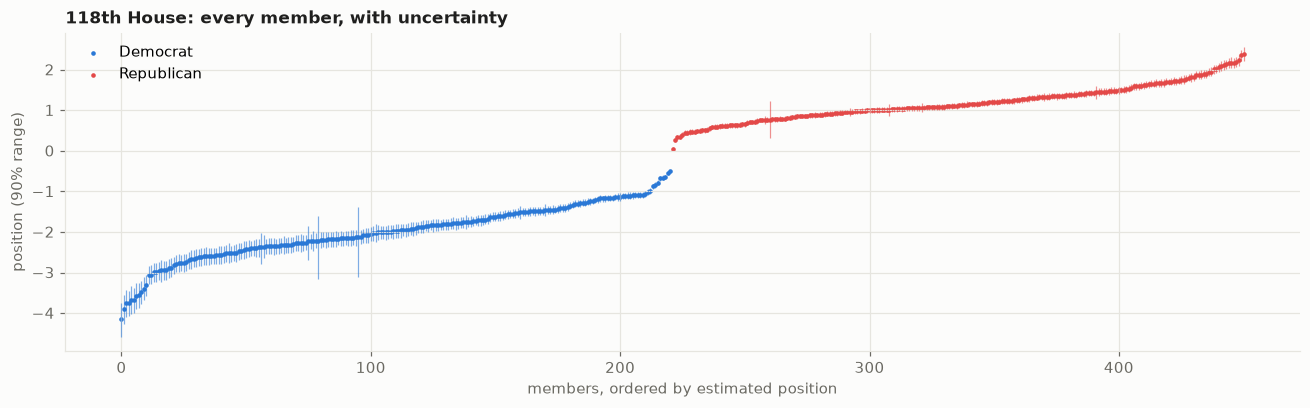

In [8]:
x = np.load('data/irt_118H.npy'); s = irt.summarize(x)
diag = json.load(open('results/irt_118H_diagnostics.json')); print('sampler diagnostics:', diag)
o = np.argsort(s['mean'])
fig, ax = plt.subplots(figsize=(12, 3.8))
for p, col in plot.PARTY.items():
    sel = (info.party.to_numpy()[o] == p)
    if not sel.any():
        continue
    idx = np.arange(len(o))[sel]
    ax.vlines(idx, s['lo'][o][sel], s['hi'][o][sel], color=col, linewidth=0.8, alpha=0.6)
    ax.scatter(idx, s['mean'][o][sel], s=4, color=col, label=p)
ax.set_xlabel('members, ordered by estimated position'); ax.set_ylabel('position (90% range)')
ax.set_title('118th House: every member, with uncertainty'); ax.legend(loc='upper left')
plt.tight_layout()
out = info[['bioname', 'party', 'state_abbrev']].assign(position=s['mean'], lo=s['lo'], hi=s['hi'],
        width=s['hi'] - s['lo'], votes_cast=m.notna().sum(1).values, nominate_dim1=info.nominate_dim1)
out.to_csv('results/irt_118H_positions.csv')

**Least certain positions:** members with few votes (sworn in late after a special election, or who left
early), and members at the **far edge** of their party: no vote separates them from their neighbours,
so the model knows they are far out but not how far.

In [9]:
out.sort_values('width', ascending=False)[['bioname', 'party', 'votes_cast', 'position', 'width']].head(6).round(2)

,bioname,party,votes_cast,position,width
icpsr,,,,,
22382,"LEE CARTER, Erica",Democrat,50,-2.13,1.71
22381,"MCIVER, LaMonica",Democrat,63,-2.21,1.54
22383,"WIED, Tony",Republican,49,0.77,0.92
22360,"RAMIREZ, Delia",Democrat,1096,-4.14,0.84
21172,"CICILLINE, David N.",Democrat,207,-2.23,0.84
21996,"SABLAN, Gregorio Kilili Camacho",Democrat,411,-2.37,0.77


In [10]:
print('Bayesian positions vs NOMINATE:', evaluate.position_scores(out.position, out.nominate_dim1, out.party))

Bayesian positions vs NOMINATE: {'overall_r': 0.9706142138326395, 'within_Republican_spearman': 0.9040548152311558, 'within_Democrat_spearman': 0.720343632998556}


## What this shows

- Separating the parties is easy and proves little; **ordering members within their party** is the
  real test.
- Logistic PCA beats PCA where the truth is known, mainly by not dragging absentees to the middle.
- One dimension predicts 95.5% of votes; the "vote with your party" rule already gets 92.8%.
- The Bayesian model agrees best with DW-NOMINATE within party (Republicans 0.90, Democrats 0.72,
  against 0.75 / 0.67 for logistic PCA), and adds **honest uncertainty**: wide ranges for members with few votes, and a warning
  that a 1-D model can be confidently wrong about a group defined by a second dimension.